# 高・中・低のベイジアンネットワーク：構築の基本
Python (bn) カーネルで上から実行してください。**必要なコードはすべてこのNotebook内にあります**。外部のPythonファイルや入力ファイルは不要です。

今回はサンプル生成 → 構造学習 → 条件付き確率の推定 → 表示までを行います。Hill Climb（BIC / BDeuの2設定）とPCの**2種類のアルゴリズム・3設定**を実行します。
複雑な再標本化、交差検証、多重比較などは行いません。構築できることの確認が目的であり、業務への妥当性を検証した結果ではありません。

In [1]:
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from IPython.display import display
from itertools import product
from pgmpy.causal_discovery import HillClimbSearch, PC
from pgmpy.structure_score import BIC, BDeu
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator

REQUIRED = {'pgmpy': '1.1.2', 'pandas': '2.3.3', 'numpy': '2.3.5', 'scikit-learn': '1.9.0'}
versions = {name: metadata.version(name) for name in REQUIRED}
display(pd.DataFrame({'required': REQUIRED, 'installed': versions}))
assert versions == REQUIRED, 'Python (bn) カーネルとライブラリの版を確認してください。'
STATES = ['低', '中', '高']
SEED = 42
N = 1200
ESS = 10  # 条件付き確率の推定に使う事前の仮想件数

/opt/anaconda3/envs/bn/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,required,installed
pgmpy,1.1.2,1.1.2
pandas,2.3.3,2.3.3
numpy,2.3.5,2.3.5
scikit-learn,1.9.0,1.9.0


## 1. サンプルデータをdfに保持する
既存の `df` があればそのコピーを使います。なければ5項目×1,200行のサンプルを生成します。
生成時だけ数値を使い、分析では低・中・高を離散カテゴリとして扱います。高低の等間隔性や単調な関係は仮定しません。
別の実データを使う場合はこのセルより前でdfを定義し、分析対象の列だけを含めてください。

In [2]:
def make_sample(n=1200, seed=42):
    rng = np.random.default_rng(seed)
    quality = rng.choice([1, 2, 3], n, p=[.25, .45, .30])
    value = rng.choice([1, 2, 3], n, p=[.30, .40, .30])
    speed = np.where(rng.random(n) < .65, quality, rng.integers(1, 4, n))
    satisfaction = np.digitize(.5*quality + .35*value + .15*speed + rng.normal(0, .45, n), [1.6, 2.4])
    renewal = np.digitize(satisfaction + 1 + rng.normal(0, .6, n), [1.6, 2.4])
    states = np.array(STATES)
    return pd.DataFrame({'サービス品質': states[quality-1], '価格納得感': states[value-1],
                         '対応速度': states[speed-1], '満足度': states[satisfaction],
                         '継続意向': states[renewal]})

if 'df' not in globals():
    df = make_sample(N, SEED)

def prepare_data(df):
    if not isinstance(df, pd.DataFrame) or df.shape[1] < 2 or len(df) < 10:
        raise ValueError('dfには2列以上・10行以上が必要です。')
    if not df.columns.is_unique or any(not isinstance(c, str) or not c for c in df.columns):
        raise ValueError('列名は空でない一意の文字列にしてください。')
    data = df.copy(deep=True)
    for column in data:
        if data[column].isna().any() or not data[column].isin(STATES).all():
            raise ValueError(f'{column}: 欠測のない低・中・高の列を指定してください。')
        if data[column].nunique() < 2:
            raise ValueError(f'{column}: 定数列は分析対象から外してください。')
        data[column] = pd.Categorical(data[column], categories=STATES, ordered=False)
    return data

data = prepare_data(df)
state_names = {column: STATES for column in data}
display(data.head())
display(pd.DataFrame({c: data[c].value_counts().reindex(STATES, fill_value=0) for c in data}).T)
print(f'{len(data)}行 × {data.shape[1]}項目')

,サービス品質,価格納得感,対応速度,満足度,継続意向
0,高,中,高,高,高
1,中,中,低,中,高
2,高,高,低,中,中
3,中,高,低,高,高
4,低,低,低,中,高


,低,中,高
サービス品質,311,521,368
価格納得感,369,469,362
対応速度,361,485,354
満足度,327,521,352
継続意向,399,348,453


1200行 × 5項目


## 2. 構造を学習する
- **HC / BIC**：辺の追加・削除・反転でBICを改善する局所探索。親数を最大2に制限します。
- **HC / BDeu**：同じ探索方法でBDeuスコア（ESS=10）を使用します。BIC版とは別アルゴリズムではありません。
- **PC**：項目間の条件付き独立性を調べて構造を組み立てます。ここでの独立性検定はアルゴリズム内部の処理です。

PCの条件集合上限2は、親数上限2という意味ではありません。確率を推定するためDAGを一つ選びますが、同じ情報を表す別の向きがあり得ます。矢印を因果関係と断定しません。

In [3]:
learners = {
    'HC / BIC': HillClimbSearch(scoring_method=BIC(data, state_names=state_names),
        max_indegree=2, return_type='dag', show_progress=False),
    'HC / BDeu': HillClimbSearch(scoring_method=BDeu(data, equivalent_sample_size=10,
        state_names=state_names), max_indegree=2, return_type='dag', show_progress=False),
    'PC': PC(variant='stable', ci_test='chi_square', significance_level=.01,
        max_cond_vars=2, return_type='dag', n_jobs=1, show_progress=False),
}

graphs = {}
for name, learner in learners.items():
    graph = learner.fit(data).causal_graph_
    graph.add_nodes_from(data.columns)  # 孤立した項目も残す
    if not nx.is_directed_acyclic_graph(graph):
        raise ValueError(f'{name}: DAGを得られませんでした。設定とデータを確認してください。')
    graphs[name] = graph
    print(name, ':', list(graph.edges()))

HC / BIC : [('サービス品質', '対応速度'), ('サービス品質', '価格納得感'), ('満足度', 'サービス品質'), ('満足度', '価格納得感'), ('継続意向', '満足度')]
HC / BDeu : [('サービス品質', '対応速度'), ('サービス品質', '価格納得感'), ('満足度', 'サービス品質'), ('満足度', '価格納得感'), ('満足度', '対応速度'), ('継続意向', '満足度')]
PC : [('サービス品質', '満足度'), ('サービス品質', '対応速度'), ('価格納得感', '満足度'), ('満足度', '継続意向')]


## 3. 各構造の条件付き確率を推定する
全モデルで同じBDeu事前分布（ESS=10）を使います。少数の条件でも確率が0に固定されることを避ける平滑化です。
親条件数qの場合、3状態の各セルへESS/(3q)の仮想件数を配ります。推定した確率は `models` 辞書に保持します。
確率の合計が1であることを確認しますが、これは形式のチェックであり、未知のデータへの性能保証ではありません。

In [4]:
models = {}
for name, graph in graphs.items():
    if any(3**(graph.in_degree(node)+1) > 10000 for node in graph.nodes()):
        raise ValueError(f'{name}: CPTが大きすぎます。項目や親数を見直してください。')
    model = DiscreteBayesianNetwork(graph.edges())
    model.add_nodes_from(data.columns)
    estimator = DiscreteBayesianEstimator(state_names=state_names,
        prior_type='BDeu', equivalent_sample_size=ESS)
    model.add_cpds(*estimator.fit(model, data).parameters_)
    assert model.check_model()
    assert len(model.get_cpds()) == len(data.columns)
    for cpd in model.get_cpds():
        assert np.allclose(cpd.get_values().sum(axis=0), 1)
    models[name] = model

display(pd.DataFrame([{'設定': name, '項目数': len(model.nodes()),
                      '辺の数': len(model.edges()), 'CPTの数': len(model.get_cpds())}
                     for name, model in models.items()]))

,設定,項目数,辺の数,CPTの数
0,HC / BIC,5,5,5
1,HC / BDeu,5,6,5
2,PC,5,4,5


## 4. ネットワークを並べて見る
同じ配置で表示するので辺の違いを確認できます。矢印は今回採用した確率分解の方向です。線の太さは関連の強さを示しません。

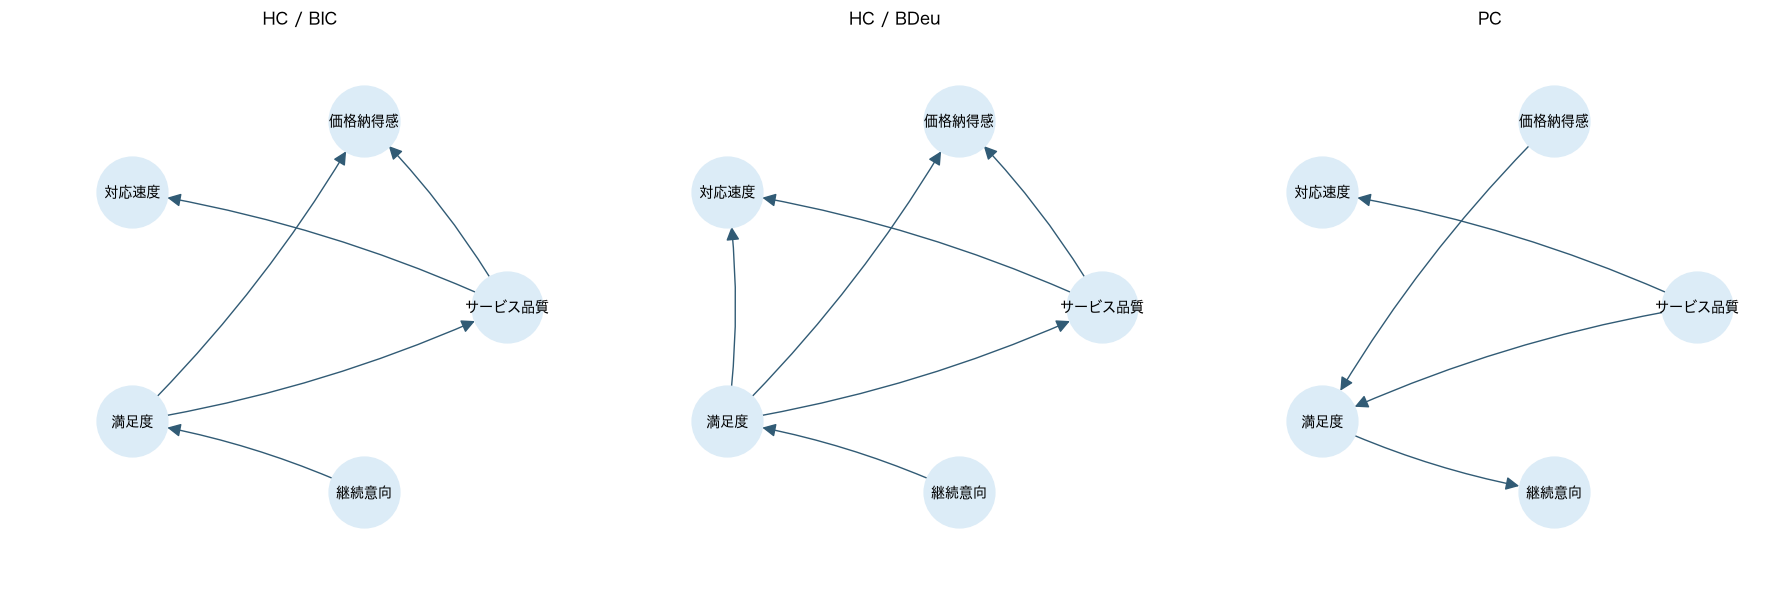

In [5]:
available_fonts = {font.name for font in fm.fontManager.ttflist}
for font in ['Hiragino Sans', 'Arial Unicode MS', 'Noto Sans CJK JP']:
    if font in available_fonts:
        plt.rcParams['font.family'] = font
        break

positions = nx.circular_layout(list(data.columns))
fig, axes = plt.subplots(1, len(graphs), figsize=(18, 6))
for ax, (name, graph) in zip(axes, graphs.items()):
    nx.draw_networkx_nodes(graph, positions, ax=ax, node_size=2600, node_color='#dcecf7')
    nx.draw_networkx_edges(graph, positions, ax=ax, node_size=2600,
        arrows=True, arrowsize=20, edge_color='#315b75', connectionstyle='arc3,rad=0.07')
    nx.draw_networkx_labels(graph, positions, ax=ax, font_size=10,
        font_family=plt.rcParams['font.family'][0])
    ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4)
    ax.set_title(name); ax.axis('off')
plt.tight_layout()
plt.show()

## 5. 確率表を読む
全モデル・全項目のCPTを `cpt_table` に保持します。各行は親条件ごとの低・中・高の確率です。
例として `継続意向` を表示します。存在しない場合は最後の列を表示します。
`親条件の件数` が0なら、その条件の確率は事前分布だけに基づきます。高い確率が必ずしも良い結果という意味ではありません。
条件付き確率は同じ条件を持つ集団の分布であり、施策を行ったときの改善効果ではありません。

In [6]:
rows = []
for name, model in models.items():
    for cpd in model.get_cpds():
        parents = cpd.variables[1:]
        for values in product(STATES, repeat=len(parents)):
            condition = dict(zip(parents, values))
            mask = np.ones(len(data), dtype=bool)
            for parent, value in condition.items():
                mask &= data[parent].to_numpy() == value
            row = {'設定': name, '項目': cpd.variable,
                   '親条件': ' / '.join(f'{k}={v}' for k,v in condition.items()) or 'なし',
                   '親条件の件数': int(mask.sum())}
            for state in STATES:
                row[state] = float(cpd.get_value(**{**condition, cpd.variable: state}))
            rows.append(row)
cpt_table = pd.DataFrame(rows)
assert np.allclose(cpt_table[STATES].sum(axis=1), 1)
target = '継続意向' if '継続意向' in data else data.columns[-1]
display(cpt_table[cpt_table['項目'] == target].reset_index(drop=True))
# 全確率表を見る場合：display(cpt_table)
# 例：models['HC / BIC'].get_cpds(target)

,設定,項目,親条件,親条件の件数,低,中,高
0,HC / BIC,継続意向,なし,1200,0.332507,0.290358,0.377135
1,HC / BDeu,継続意向,なし,1200,0.332507,0.290358,0.377135
2,PC,継続意向,満足度=低,327,0.823747,0.157753,0.018500
3,PC,継続意向,満足度=中,521,0.240517,0.475101,0.284382
4,PC,継続意向,満足度=高,352,0.011570,0.141026,0.847405


## ここまででできたこと
3設定のネットワークと、それぞれの条件付き確率を構築しました。構造は `graphs`、確率を含むモデルは `models`、全確率表は `cpt_table` から参照できます。

この段階では「どれが業務上もっとも良いか」は判断しません。まず変数定義、図の関係、確率表の意味を確認してください。必要になった段階で、別データでの評価や安定性の検証を追加できます。